In [2]:
import numpy as np
from numpy import linalg as la # linear algebra
A = np.array([ [-4,-6], [3, 5] ])

w, v = la.eig(A)
print(w) # eigenvalue
print(v)

[-1.  2.]
[[-0.89442719  0.70710678]
 [ 0.4472136  -0.70710678]]


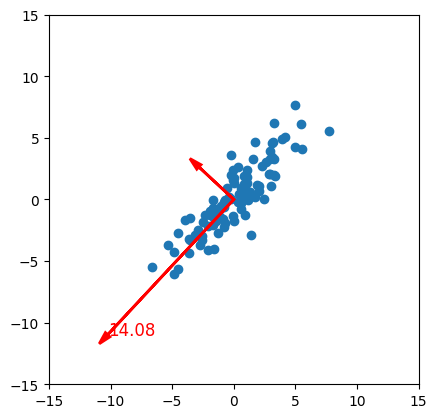

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import math
from numpy import linalg as la # linear algebra

THETA = 45 # rotation angle
num_samples = 100
X = np.random.randn(num_samples, 2)
X[:, 0] = X[:, 0] * 4 # make an ellipse
rotation_matrix = np.array( [[ math.cos(math.radians(THETA)), -math.sin(math.radians(THETA)) ],
                    [ math.sin(math.radians(THETA)), math.cos(math.radians(THETA)) ]] )

X = np.matmul(rotation_matrix, X.T).T # rotation
A = np.cov(X.T) # covariance matrix
fig, ax = plt.subplots()

ax.scatter(X[:, 0], X[:, 1], marker = 'o')
ax.set_aspect('equal')
ax.set_ylim(-15, 15)
ax.set_xlim(-15, 15)


eigvals, eigvecs = la.eig(A)
origin = np.array([0, 0])
for i in range(2):
    vec = eigvecs[:, i]
    val = eigvals[i]
    scale = np.sqrt(val)
    ax.arrow(origin[0], origin[1],
        vec[0]*scale*4, vec[1]*scale*4, # 4 for extra scaling
        head_width=0.5, head_length=1, fc='red', ec='red',
        linewidth=2)
    dx = vec[0] * scale * 4
    dy = vec[1] * scale * 4
ax.text(dx, dy, f"{val:.2f}", fontsize=12, color='red')

plt.show()

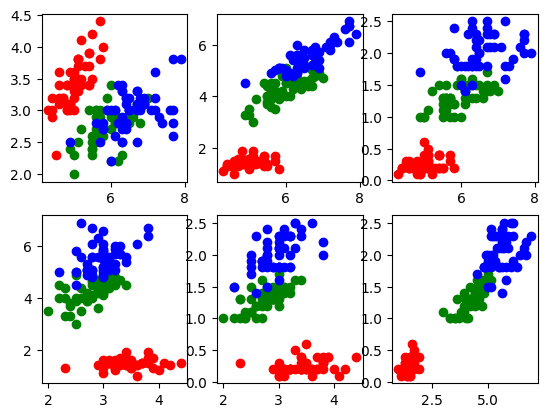

In [ ]:
import matplotlib.pyplot as plt
from sklearn import datasets
def data_plot(data, target, fig_index):
    plt.subplot(2, 3, fig_index)
    plt.scatter(data[target == 0, 0], data[target == 0, 1], c = 'red')
    plt.scatter(data[target == 1, 0], data[target == 1, 1], c = 'green')
    plt.scatter(data[target == 2, 0], data[target == 2, 1], c = 'blue')
    return
iris = datasets.load_iris()
X = iris.data
Y = iris.target
index = [(0, 1), (0, 2), (0, 3), (1, 2), (1, 3), (2, 3)]
for i in range(0, 6) :
    data = X[:, index[i]]
    data_plot(data, Y, i + 1)
plt.show()

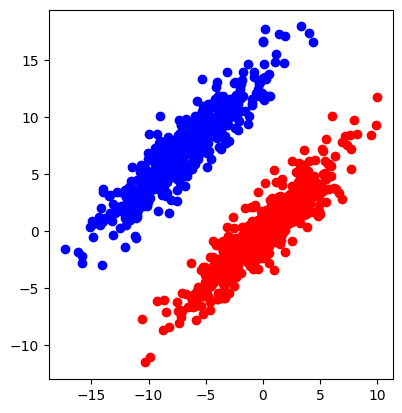

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import math
from numpy import linalg as la # linear algebra

THETA = 45 # rotation angle
num_samples = 500

def generate_data(offset, target) :
    X = np.random.randn(num_samples, 2)
    X[:, 0] = X[:, 0] * 5
    rotation_matrix = np.array( [ # rotation matrix
      [ math.cos(math.radians(THETA)), -math.sin(math.radians(THETA)) ],
      [ math.sin(math.radians(THETA)), math.cos(math.radians(THETA)) ]] )
    X = np.matmul(rotation_matrix, X.T).T # rotation
    X[:, 0] += offset[0]; X[:, 1] += offset[1] # move center
    Y = np.ones((num_samples, 1)) * target

    return X, Y

X1, Y1 = generate_data([0, 0], 0)
X2, Y2 = generate_data([-7, 7], 1)
fig, ax = plt.subplots()
ax.scatter(X1[:, 0], X1[:, 1], c='r')
ax.scatter(X2[:, 0], X2[:, 1], c='b')
ax.set_aspect('equal')
plt.show()

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


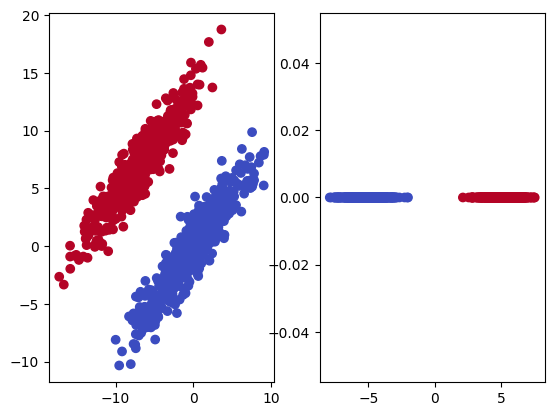

In [ ]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
THETA = 45
num_samples = 500
X1, Y1 = generate_data([0, 0], 0)
X2, Y2 = generate_data([-7, 7], 1)
X = np.concatenate((X1, X2), axis=0)
Y = np.concatenate((Y1, Y2), axis=0)
lda = LDA(n_components=1)
x_lda = lda.fit_transform(X, Y)
plt.subplot(1, 2, 1)
plt.scatter(X[:, 0], X[:, 1], c=Y, cmap='coolwarm')
plt.subplot(1, 2, 2)
plt.scatter(x_lda, np.zeros_like(x_lda), c=Y, cmap='coolwarm')
plt.show()